# FinSight AI: Transaction Analytics and Data Profiling

This notebook builds a reliable analytical foundation for FinSight AI. It profiles and cleans financial transactions, engineers time features, explores spending behavior, calculates KPIs, segments customers, investigates statistical anomalies, and evaluates readiness for future machine-learning and AI-powered analytics.

In [4]:
import pandas as pd

In [5]:
customers = pd.read_csv("../data/raw/customers.csv")

In [6]:
customers.head()

,customer_id,first_name,last_name,email,date_of_birth,gender,country,city,occupation,annual_income,account_type,onboarding_date
0,c-00001,Michael,Williams,michael.williams@example.com,1990-02-21 00:00:00,Female,Australia,London,Retired,90868.36,Basic,2023-02-20 23:04:16
1,c-00002,Patricia,Jones,patricia.jones@example.com,1993-06-21 00:00:00,Female,USA,Seattle,Engineer,73547.57,Basic,2023-05-31 12:58:05
2,c-00003,Linda,Williams,linda.williams@example.com,1982-04-25 00:00:00,Female,USA,Austin,Teacher,115770.79,Premium,2023-05-25 12:01:59
3,c-00004,Robert,Martinez,robert.martinez@example.com,1979-10-23 00:00:00,Male,USA,Seattle,Student,40969.23,Basic,2023-08-11 00:35:59
4,c-00005,Michael,Miller,michael.miller@example.com,2000-09-04 00:00:00,Female,USA,London,Student,98650.54,Basic,2023-10-23 23:39:35


In [17]:
customers.shape

(10000, 12)

In [18]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   customer_id      10000 non-null  object 
 1   first_name       10000 non-null  object 
 2   last_name        10000 non-null  object 
 3   email            10000 non-null  object 
 4   date_of_birth    9530 non-null   object 
 5   gender           10000 non-null  object 
 6   country          10000 non-null  object 
 7   city             9804 non-null   object 
 8   occupation       10000 non-null  object 
 9   annual_income    10000 non-null  float64
 10  account_type     10000 non-null  object 
 11  onboarding_date  10000 non-null  object 
dtypes: float64(1), object(11)
memory usage: 937.6+ KB


In [19]:
customers.isnull().sum()

customer_id          0
first_name           0
last_name            0
email                0
date_of_birth      470
gender               0
country              0
city               196
occupation           0
annual_income        0
account_type         0
onboarding_date      0
dtype: int64

In [20]:
customers.isnull().sum() / len(customers) * 100

customer_id        0.00
first_name         0.00
last_name          0.00
email              0.00
date_of_birth      4.70
gender             0.00
country            0.00
city               1.96
occupation         0.00
annual_income      0.00
account_type       0.00
onboarding_date    0.00
dtype: float64

In [21]:
customers.duplicated().sum()

np.int64(0)

In [7]:
transactions = pd.read_csv("../data/raw/transactions.csv")

In [8]:
transactions.head()

,transaction_id,customer_id,account_id,transaction_date,amount,transaction_type,merchant_category,payment_method,location,status
0,t-000001,c-05235,a-07271,2023-05-13 18:21:18,3.98,Purchase,Uber,Wire,Local,Completed
1,t-000002,c-00624,a-00861,2023-03-10 04:17:49,81.81,Transfer,Restaurant,Wire,Local,Completed
2,t-000003,c-03875,a-05391,2024-01-21 04:18:40,39.66,Purchase,Uber,Card,Local,Completed
3,t-000004,c-09632,a-13419,2024-02-11 04:14:06,7.22,Purchase,Amazon,ACH,Local,Completed
4,t-000005,c-03733,a-05192,2023-04-23 12:39:22,57.54,Transfer,Uber,Card,Local,Completed


In [9]:
transactions.shape

(100050, 10)

In [10]:
transactions.duplicated().sum()

np.int64(50)

In [26]:
transactions[transactions.duplicated()]


,transaction_id,customer_id,account_id,transaction_date,amount,transaction_type,merchant_category,payment_method,location,status
100000,t-075722,c-07408,a-10301,2023-11-17 02:27:00,6.00,Purchase,Amazon,Card,Local,Failed
100001,t-080185,c-00061,a-00080,2023-02-03 09:02:29,76.54,Withdrawal,TechStore,ACH,Local,Completed
100002,t-019865,c-06345,a-08831,2023-03-04 07:33:14,204.36,Purchase,TechStore,Card,Local,Completed
100003,t-076700,c-04203,a-05843,2023-05-31 08:34:12,8.44,Purchase,TechStore,Card,Local,Completed
100004,t-092992,c-01961,a-02720,2023-02-17 06:45:04,1.78,Purchase,Gas,Wallet,Local,Completed
100005,t-076435,c-02410,a-03345,2023-10-28 22:50:11,153.50,Purchase,Amazon,Wallet,Local,Completed
100006,t-084005,c-03174,a-04418,2023-12-13 17:43:18,57.55,Withdrawal,TechStore,Card,Local,Completed
100007,t-080918,c-03132,a-04357,2023-10-25 21:33:34,32.04,Purchase,Uber,Wire,Local,Completed
100008,t-060768,c-03862,a-05375,2023-11-12 09:30:37,13.05,Transfer,Uber,Wallet,Local,Completed
100009,t-050075,c-06934,a-09636,2023-07-12 18:05:15,47.75,Purchase,Gas,Wallet,Local,Failed


In [11]:
transactions = pd.read_csv("../data/raw/transactions.csv")

In [12]:
transactions.isnull().sum()

transaction_id       0
customer_id          0
account_id           0
transaction_date     0
amount               0
transaction_type     0
merchant_category    0
payment_method       0
location             0
status               0
dtype: int64

In [13]:
transactions.duplicated().sum()

np.int64(50)

In [14]:
transactions[transactions.duplicated(keep=False)].sort_values("transaction_id").head(20)

,transaction_id,customer_id,account_id,transaction_date,amount,transaction_type,merchant_category,payment_method,location,status
149,t-000150,c-05873,a-08155,2023-11-14 14:10:18,7.76,Purchase,Restaurant,Card,Local,Completed
100016,t-000150,c-05873,a-08155,2023-11-14 14:10:18,7.76,Purchase,Restaurant,Card,Local,Completed
1761,t-001762,c-08817,a-12255,2023-01-27 23:18:10,40.57,Purchase,Amazon,Card,Foreign,Completed
100017,t-001762,c-08817,a-12255,2023-01-27 23:18:10,40.57,Purchase,Amazon,Card,Foreign,Completed
2495,t-002496,c-02340,a-03250,2023-12-12 03:19:35,9.18,Withdrawal,Gas,ACH,Local,Completed
100021,t-002496,c-02340,a-03250,2023-12-12 03:19:35,9.18,Withdrawal,Gas,ACH,Local,Completed
4727,t-004728,c-00175,a-00233,2024-01-23 05:01:10,52.95,Transfer,Gas,Wire,Local,Completed
100048,t-004728,c-00175,a-00233,2024-01-23 05:01:10,52.95,Transfer,Gas,Wire,Local,Completed
11405,t-011406,c-03169,a-04410,2023-02-11 18:12:11,7.02,Transfer,TechStore,ACH,Local,Completed
100037,t-011406,c-03169,a-04410,2023-02-11 18:12:11,7.02,Transfer,TechStore,ACH,Local,Completed


In [15]:
transactions = transactions.drop_duplicates()

In [16]:
transactions.duplicated().sum()

np.int64(0)

In [17]:
transactions.shape

(100000, 10)

In [18]:
transactions.dtypes

transaction_id        object
customer_id           object
account_id            object
transaction_date      object
amount               float64
transaction_type      object
merchant_category     object
payment_method        object
location              object
status                object
dtype: object

In [19]:
transactions["transaction_date"] = pd.to_datetime(
    transactions["transaction_date"]
)

In [20]:
transactions.dtypes

transaction_id               object
customer_id                  object
account_id                   object
transaction_date     datetime64[ns]
amount                      float64
transaction_type             object
merchant_category            object
payment_method               object
location                     object
status                       object
dtype: object

In [21]:
transactions["transaction_date"].dt.month

0         5
1         3
2         1
3         2
4         4
         ..
99995     1
99996    12
99997     1
99998     2
99999    12
Name: transaction_date, Length: 100000, dtype: int32

In [22]:
transactions["transaction_date"].dt.day_name()

0         Saturday
1           Friday
2           Sunday
3           Sunday
4           Sunday
           ...    
99995       Friday
99996    Wednesday
99997     Thursday
99998    Wednesday
99999     Saturday
Name: transaction_date, Length: 100000, dtype: object

In [23]:
transactions["transaction_type"].value_counts()

transaction_type
Purchase      70009
Transfer      19951
Withdrawal    10040
Name: count, dtype: int64

In [24]:
transactions["merchant_category"].value_counts()

merchant_category
Restaurant    14525
Uber          14381
TechStore     14292
Gas           14244
Airlines      14221
Grocery       14205
Amazon        14132
Name: count, dtype: int64

In [25]:
transactions["payment_method"].value_counts()

payment_method
Card      60183
ACH       19935
Wallet    14926
Wire       4956
Name: count, dtype: int64

In [26]:
transactions["status"].value_counts()

status
Completed    89937
Failed        8124
Pending       1939
Name: count, dtype: int64

In [27]:
transactions["location"].value_counts()

location
Local      89983
Foreign    10017
Name: count, dtype: int64

In [29]:
transactions["amount"].describe()

count    100000.000000
mean         67.692682
std         118.003702
min           0.170000
25%          14.660000
50%          32.860000
75%          74.000000
max        5235.620000
Name: amount, dtype: float64

In [30]:
(transactions["amount"] <= 0).sum()

np.int64(0)

In [31]:
q1 = transactions["amount"].quantile(0.25)
q3 = transactions["amount"].quantile(0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr

transactions[transactions["amount"] > upper_bound].shape[0]

9273

In [32]:
transactions["transaction_date"].min(), transactions["transaction_date"].max()

(Timestamp('2023-01-01 00:01:24'), Timestamp('2024-02-29 23:49:35'))

## Data Quality and Profiling

This section validates the cleaned transaction data before feature engineering and exploratory analysis.

In [33]:
date_validation = {
    "dtype_is_datetime": pd.api.types.is_datetime64_any_dtype(transactions["transaction_date"]),
    "missing_dates": int(transactions["transaction_date"].isna().sum()),
    "earliest_date": transactions["transaction_date"].min(),
    "latest_date": transactions["transaction_date"].max(),
    "future_dates": int((transactions["transaction_date"] > pd.Timestamp.now()).sum()),
}

date_validation

{'dtype_is_datetime': True,
 'missing_dates': 0,
 'earliest_date': Timestamp('2023-01-01 00:01:24'),
 'latest_date': Timestamp('2024-02-29 23:49:35'),
 'future_dates': 0}

### Identifier, Cardinality, and Frequency Checks

Identifiers are profiled for uniqueness and repetition rather than treated as ordinary categories. Repeated customers and accounts are expected in transaction data, but duplicate transaction identifiers require investigation.

In [34]:
identifier_profile = transactions[["transaction_id", "customer_id", "account_id"]].nunique()
duplicate_transaction_ids = int(transactions["transaction_id"].duplicated().sum())

customer_transaction_counts = transactions.groupby("customer_id").size()
account_transaction_counts = transactions.groupby("account_id").size()

categorical_cardinality = transactions[[
    "transaction_type", "merchant_category", "payment_method", "location", "status"
]].nunique()

monthly_transaction_counts = (
    transactions["transaction_date"].dt.to_period("M")
    .value_counts()
    .sort_index()
)

profiling_results = {
    "row_count": len(transactions),
    "column_count": transactions.shape[1],
    "identifier_unique_counts": identifier_profile.to_dict(),
    "duplicate_transaction_id_count": duplicate_transaction_ids,
    "customer_count": int(customer_transaction_counts.size),
    "account_count": int(account_transaction_counts.size),
    "max_transactions_per_customer": int(customer_transaction_counts.max()),
    "max_transactions_per_account": int(account_transaction_counts.max()),
    "categorical_cardinality": categorical_cardinality.to_dict(),
    "month_count": int(monthly_transaction_counts.size),
}

profiling_results

{'row_count': 100000,
 'column_count': 10,
 'identifier_unique_counts': {'transaction_id': 100000,
  'customer_id': 9999,
  'account_id': 13943},
 'duplicate_transaction_id_count': 0,
 'customer_count': 9999,
 'account_count': 13943,
 'max_transactions_per_customer': 36,
 'max_transactions_per_account': 19,
 'categorical_cardinality': {'transaction_type': 3,
  'merchant_category': 7,
  'payment_method': 4,
  'location': 2,
  'status': 3},
 'month_count': 14}

## Data Cleaning Decisions

The earlier checks found genuine full-row duplicates, which were removed. The following checks look for remaining formatting inconsistencies or non-numeric amounts before making any additional cleaning change.

In [35]:
categorical_columns = [
    "transaction_type", "merchant_category", "payment_method", "location", "status"
]

categorical_quality = {}
for column in categorical_columns:
    values = transactions[column].astype("string")
    categorical_quality[column] = {
        "missing_values": int(values.isna().sum()),
        "blank_values": int(values.str.strip().eq("").sum()),
        "leading_or_trailing_whitespace": int(values.ne(values.str.strip()).sum()),
        "unique_values": sorted(values.dropna().unique().tolist()),
    }

numeric_amount = pd.to_numeric(transactions["amount"], errors="coerce")
amount_conversion_failures = int(numeric_amount.isna().sum() - transactions["amount"].isna().sum())

cleaning_validation = {
    "amount_dtype_before_cleaning": str(transactions["amount"].dtype),
    "amount_conversion_failures": amount_conversion_failures,
    "transaction_date_dtype": str(transactions["transaction_date"].dtype),
    "duplicate_rows": int(transactions.duplicated().sum()),
    "duplicate_transaction_ids": int(transactions["transaction_id"].duplicated().sum()),
    "categorical_quality": categorical_quality,
}

cleaning_validation

{'amount_dtype_before_cleaning': 'float64',
 'amount_conversion_failures': 0,
 'transaction_date_dtype': 'datetime64[ns]',
 'duplicate_rows': 0,
 'duplicate_transaction_ids': 0,
 'categorical_quality': {'transaction_type': {'missing_values': 0,
   'blank_values': 0,
   'leading_or_trailing_whitespace': 0,
   'unique_values': ['Purchase', 'Transfer', 'Withdrawal']},
  'merchant_category': {'missing_values': 0,
   'blank_values': 0,
   'leading_or_trailing_whitespace': 0,
   'unique_values': ['Airlines',
    'Amazon',
    'Gas',
    'Grocery',
    'Restaurant',
    'TechStore',
    'Uber']},
  'payment_method': {'missing_values': 0,
   'blank_values': 0,
   'leading_or_trailing_whitespace': 0,
   'unique_values': ['ACH', 'Card', 'Wallet', 'Wire']},
  'location': {'missing_values': 0,
   'blank_values': 0,
   'leading_or_trailing_whitespace': 0,
   'unique_values': ['Foreign', 'Local']},
  'status': {'missing_values': 0,
   'blank_values': 0,
   'leading_or_trailing_whitespace': 0,
   'un

In [36]:
numeric_amount = pd.to_numeric(transactions["amount"], errors="raise")
transactions["amount"] = numeric_amount
transactions = transactions.reset_index(drop=True)

final_cleaning_check = {
    "shape": transactions.shape,
    "index_is_sequential": transactions.index.equals(pd.RangeIndex(start=0, stop=len(transactions))),
    "amount_dtype": str(transactions["amount"].dtype),
    "date_dtype": str(transactions["transaction_date"].dtype),
    "missing_values": int(transactions.isna().sum().sum()),
    "duplicate_rows": int(transactions.duplicated().sum()),
}

final_cleaning_check

{'shape': (100000, 10),
 'index_is_sequential': True,
 'amount_dtype': 'float64',
 'date_dtype': 'datetime64[ns]',
 'missing_values': 0,
 'duplicate_rows': 0}

## Feature Engineering

Calendar features make it possible to compare transaction activity by year, month, weekday, hour, week, and quarter.

In [37]:
transactions["transaction_year"] = transactions["transaction_date"].dt.year
transactions["transaction_month"] = transactions["transaction_date"].dt.month
transactions["transaction_month_name"] = transactions["transaction_date"].dt.month_name()
transactions["transaction_day"] = transactions["transaction_date"].dt.day
transactions["transaction_day_name"] = transactions["transaction_date"].dt.day_name()
transactions["transaction_hour"] = transactions["transaction_date"].dt.hour
transactions["transaction_week"] = transactions["transaction_date"].dt.isocalendar().week.astype(int)
transactions["transaction_quarter"] = transactions["transaction_date"].dt.quarter

feature_columns = [
    "transaction_year", "transaction_month", "transaction_month_name",
    "transaction_day", "transaction_day_name", "transaction_hour",
    "transaction_week", "transaction_quarter"
]

feature_validation = {
    "created_columns": [column for column in feature_columns if column in transactions.columns],
    "missing_feature_values": int(transactions[feature_columns].isna().sum().sum()),
    "hour_range": (int(transactions["transaction_hour"].min()), int(transactions["transaction_hour"].max())),
    "quarter_values": sorted(transactions["transaction_quarter"].unique().tolist()),
}

feature_validation

{'created_columns': ['transaction_year',
  'transaction_month',
  'transaction_month_name',
  'transaction_day',
  'transaction_day_name',
  'transaction_hour',
  'transaction_week',
  'transaction_quarter'],
 'missing_feature_values': 0,
 'hour_range': (0, 23),
 'quarter_values': [1, 2, 3, 4]}

## Exploratory Data Analysis

These charts describe transaction volume, amounts, categories, status, payment methods, and location. Potential outliers are retained and shown rather than deleted.

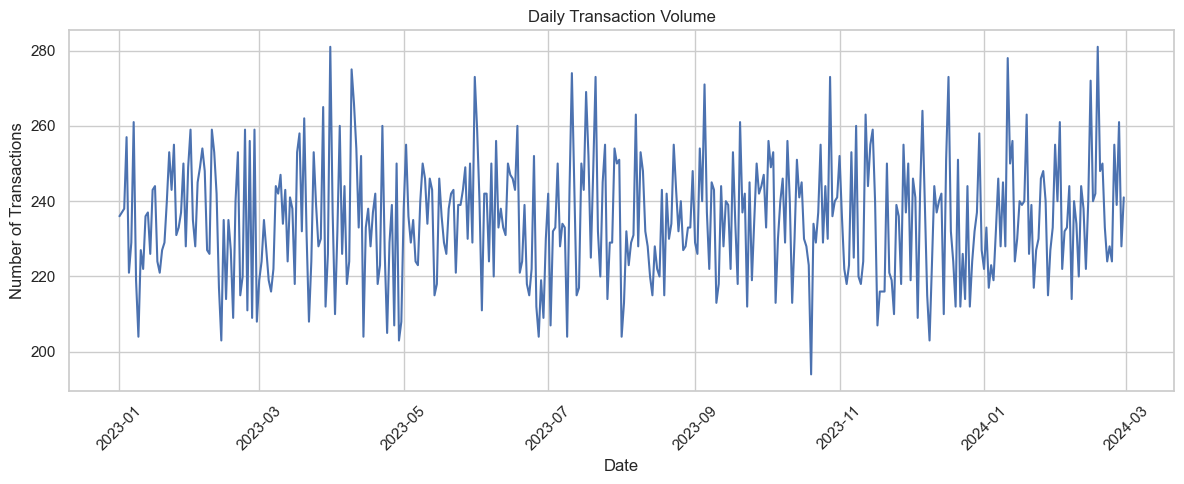

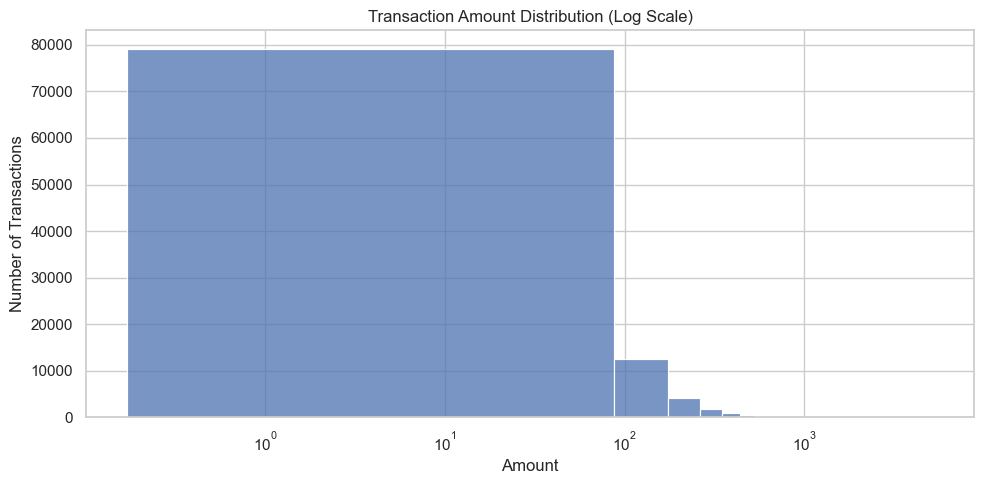

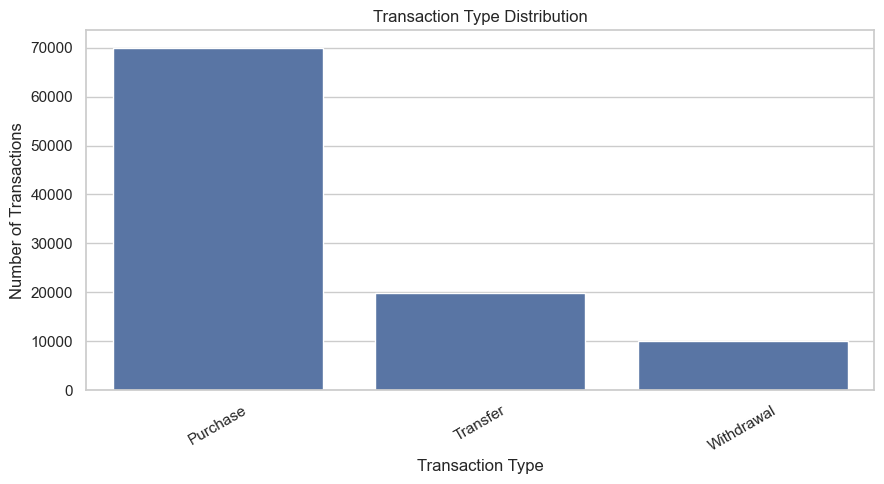

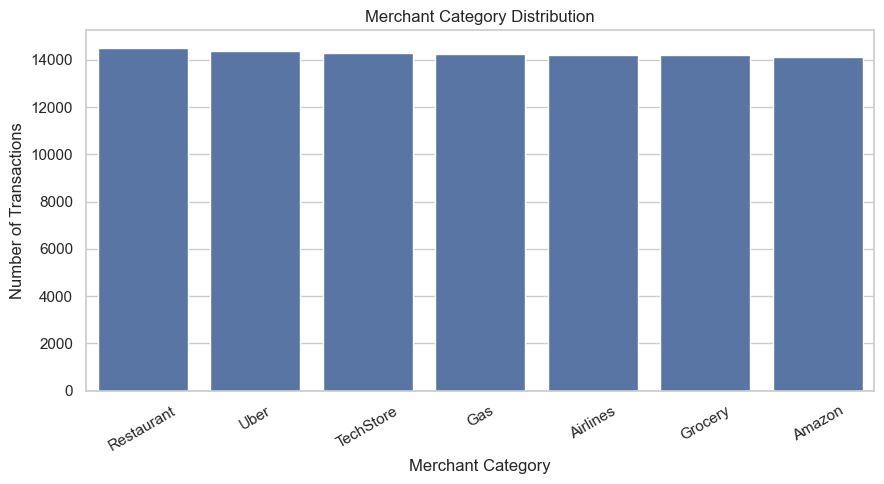

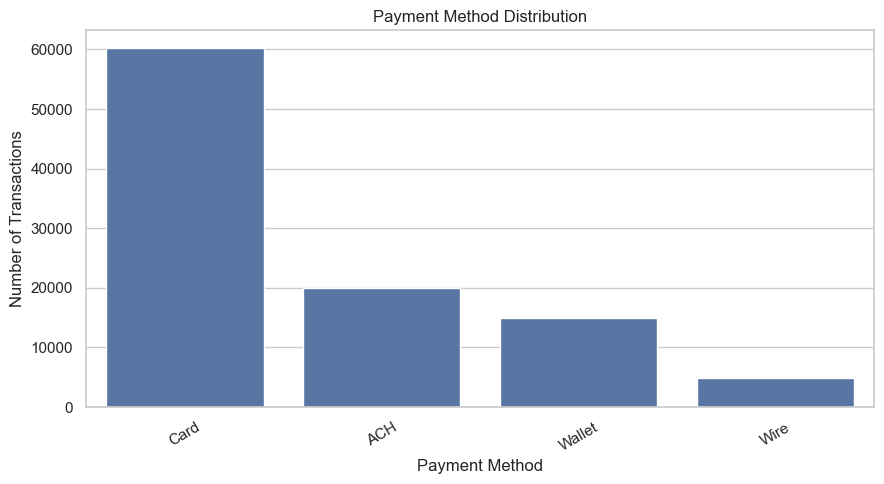

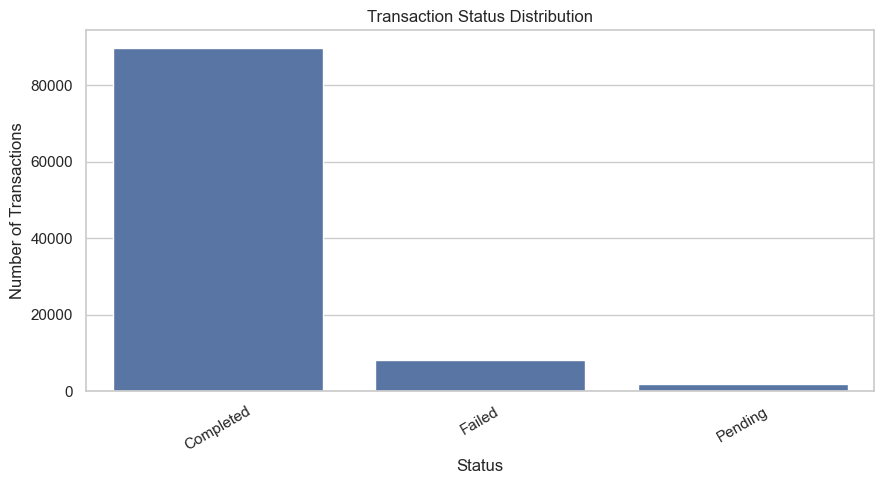

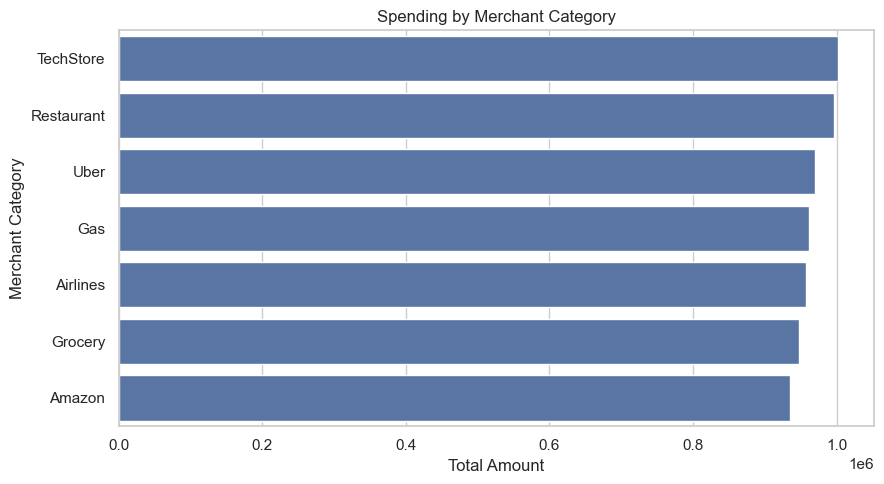

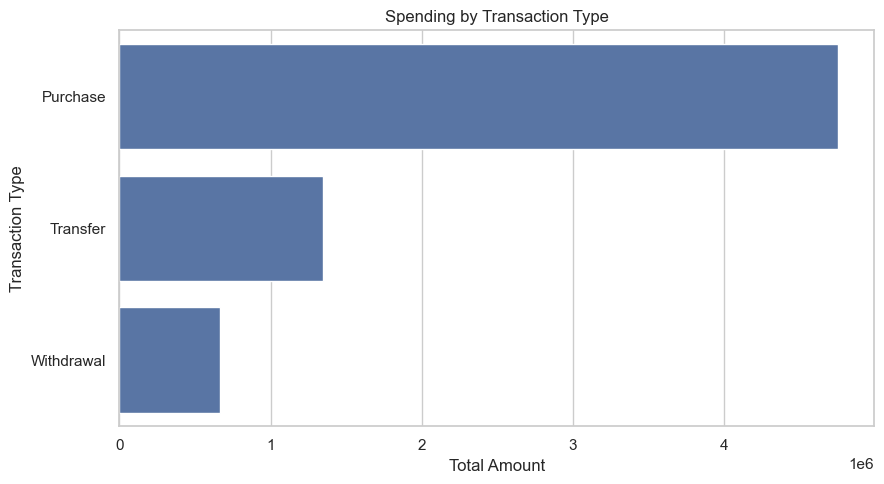

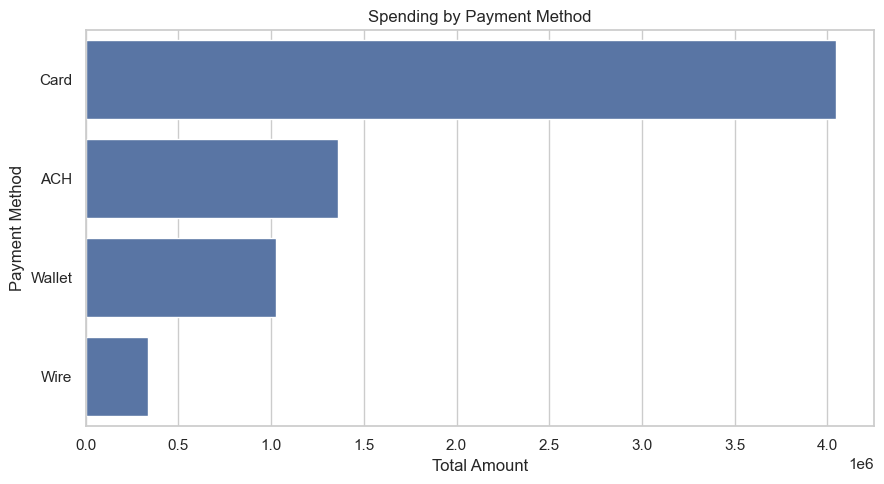

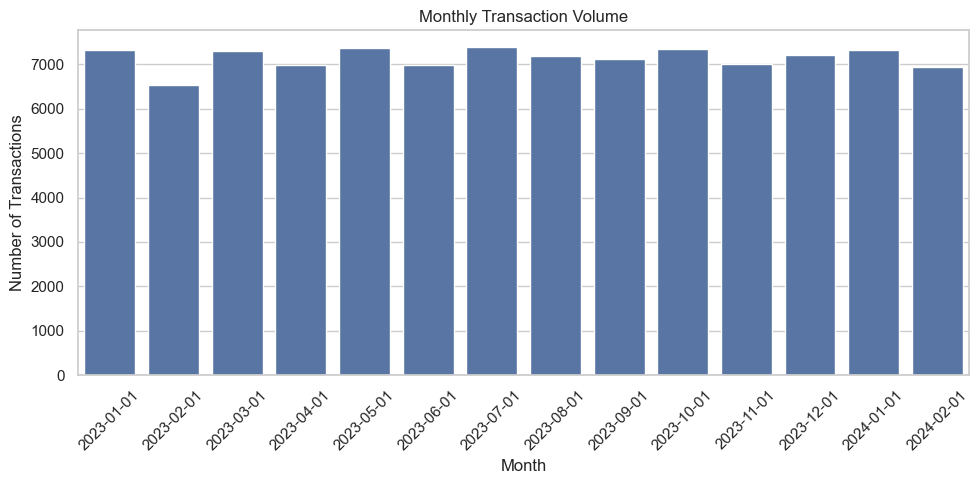

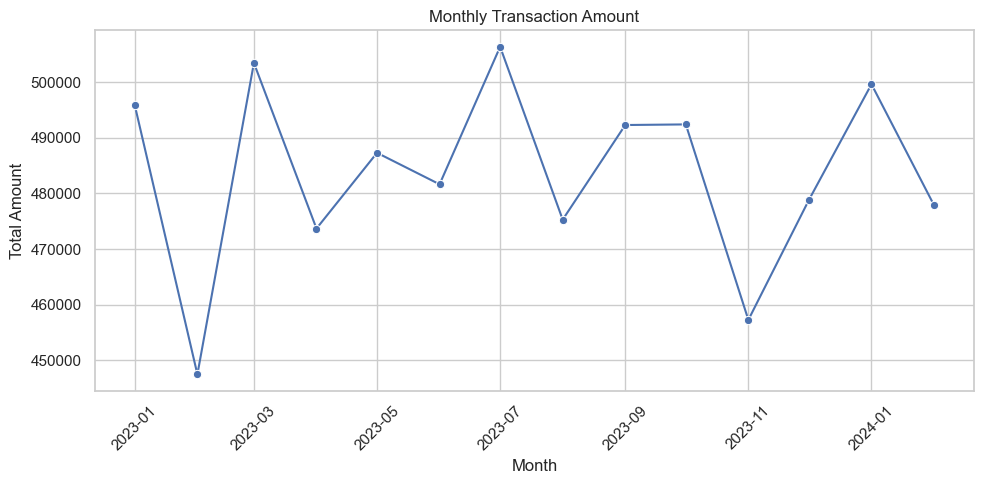

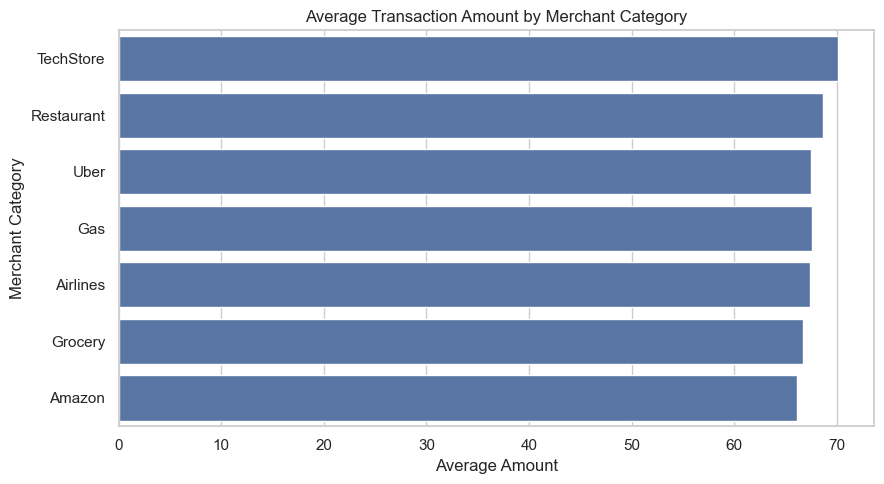

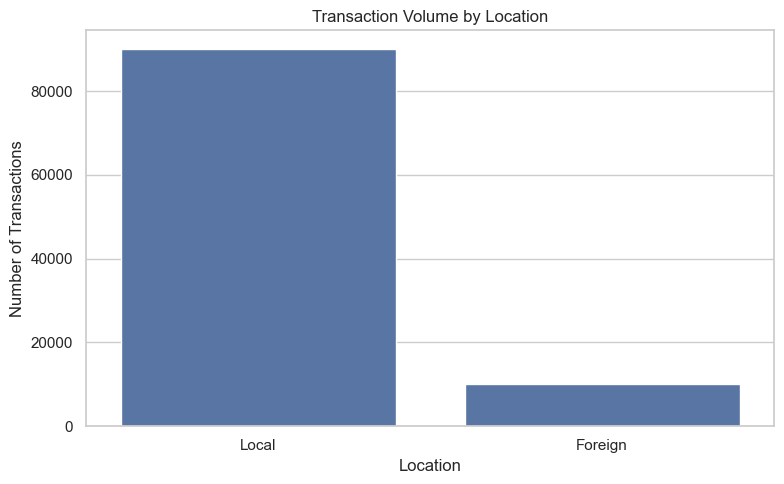

{'daily_rows': 425,
 'monthly_rows': 14,
 'category_rows': 7,
 'type_rows': 3,
 'payment_rows': 4,
 'location_rows': 2}

In [38]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

transactions["transaction_day_date"] = transactions["transaction_date"].dt.normalize()

daily_summary = (
    transactions.groupby("transaction_day_date")
    .agg(transaction_count=("transaction_id", "count"), total_amount=("amount", "sum"))
    .reset_index()
)

monthly_summary = (
    transactions.assign(transaction_period=transactions["transaction_date"].dt.to_period("M"))
    .groupby("transaction_period")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum"),
        average_amount=("amount", "mean"),
    )
    .reset_index()
)
monthly_summary["month"] = monthly_summary["transaction_period"].dt.to_timestamp()

category_summary = (
    transactions.groupby("merchant_category")
    .agg(transaction_count=("transaction_id", "count"), total_amount=("amount", "sum"), average_amount=("amount", "mean"))
    .sort_values("total_amount", ascending=False)
)

type_summary = (
    transactions.groupby("transaction_type")
    .agg(transaction_count=("transaction_id", "count"), total_amount=("amount", "sum"), average_amount=("amount", "mean"))
    .sort_values("total_amount", ascending=False)
)

payment_summary = (
    transactions.groupby("payment_method")
    .agg(transaction_count=("transaction_id", "count"), total_amount=("amount", "sum"), average_amount=("amount", "mean"))
    .sort_values("total_amount", ascending=False)
)

location_summary = (
    transactions.groupby("location")
    .agg(transaction_count=("transaction_id", "count"), total_amount=("amount", "sum"), average_amount=("amount", "mean"))
    .sort_values("total_amount", ascending=False)
)

fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=daily_summary, x="transaction_day_date", y="transaction_count", ax=ax)
ax.set_title("Daily Transaction Volume")
ax.set_xlabel("Date")
ax.set_ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=transactions, x="amount", bins=60, ax=ax)
ax.set_xscale("log")
ax.set_title("Transaction Amount Distribution (Log Scale)")
ax.set_xlabel("Amount")
ax.set_ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

plot_specs = [
    ("transaction_type", "Transaction Type Distribution", "Transaction Type"),
    ("merchant_category", "Merchant Category Distribution", "Merchant Category"),
    ("payment_method", "Payment Method Distribution", "Payment Method"),
    ("status", "Transaction Status Distribution", "Status"),
]
for column, title, xlabel in plot_specs:
    fig, ax = plt.subplots(figsize=(9, 5))
    order = transactions[column].value_counts().index
    sns.countplot(data=transactions, x=column, order=order, ax=ax)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Number of Transactions")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

bar_specs = [
    (category_summary, "total_amount", "Spending by Merchant Category", "Merchant Category"),
    (type_summary, "total_amount", "Spending by Transaction Type", "Transaction Type"),
    (payment_summary, "total_amount", "Spending by Payment Method", "Payment Method"),
]
for summary, value_column, title, xlabel in bar_specs:
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.barplot(x=summary[value_column], y=summary.index, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Total Amount")
    ax.set_ylabel(xlabel)
    plt.tight_layout()
    plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=monthly_summary, x="month", y="transaction_count", ax=ax)
ax.set_title("Monthly Transaction Volume")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=monthly_summary, x="month", y="total_amount", marker="o", ax=ax)
ax.set_title("Monthly Transaction Amount")
ax.set_xlabel("Month")
ax.set_ylabel("Total Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=category_summary.reset_index(), x="average_amount", y="merchant_category", ax=ax)
ax.set_title("Average Transaction Amount by Merchant Category")
ax.set_xlabel("Average Amount")
ax.set_ylabel("Merchant Category")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=location_summary.reset_index(), x="location", y="transaction_count", ax=ax)
ax.set_title("Transaction Volume by Location")
ax.set_xlabel("Location")
ax.set_ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

eda_summary = {
    "daily_rows": len(daily_summary),
    "monthly_rows": len(monthly_summary),
    "category_rows": len(category_summary),
    "type_rows": len(type_summary),
    "payment_rows": len(payment_summary),
    "location_rows": len(location_summary),
}

eda_summary

### EDA Summary

The cleaned dataset covers 425 active dates across 14 months. Daily volume fluctuates around a stable level, monthly volume ranges from 6,536 to 7,395 transactions, and transaction amounts are strongly right-skewed. Purchases, cards, and local transactions dominate by count, while TechStore leads total merchant-category spend.

## Financial KPIs

These tables provide the core financial measures that can later power dashboards and AI-generated answers.

In [39]:
kpi_summary = pd.DataFrame({
    "metric": [
        "Total transaction amount", "Total transactions", "Average transaction amount",
        "Median transaction amount", "Minimum transaction amount", "Maximum transaction amount"
    ],
    "value": [
        transactions["amount"].sum(),
        transactions.shape[0],
        transactions["amount"].mean(),
        transactions["amount"].median(),
        transactions["amount"].min(),
        transactions["amount"].max(),
    ],
})

status_summary = (
    transactions["status"].value_counts()
    .rename_axis("status")
    .reset_index(name="transaction_count")
)
status_summary["percentage"] = status_summary["transaction_count"] / len(transactions) * 100

print("Core KPIs")
display(kpi_summary)
print("\nTransaction type summary")
display(type_summary.reset_index())
print("\nMerchant category summary")
display(category_summary.reset_index())
print("\nPayment method summary")
display(payment_summary.reset_index())
print("\nStatus summary")
display(status_summary)
print("\nMonthly summary")
display(monthly_summary)


Core KPIs


,metric,value
0,Total transaction amount,6.769268e+06
1,Total transactions,1.000000e+05
2,Average transaction amount,6.769268e+01
3,Median transaction amount,3.286000e+01
4,Minimum transaction amount,1.700000e-01
5,Maximum transaction amount,5.235620e+03



Transaction type summary


,transaction_type,transaction_count,total_amount,average_amount
0,Purchase,70009,4753555.77,67.899210
1,Transfer,19951,1349697.91,67.650640
2,Withdrawal,10040,666014.49,66.336105



Merchant category summary


...

,payment_method,transaction_count,total_amount,average_amount
0,Card,60183,4049034.51,67.278708
1,ACH,19935,1358277.43,68.135311
2,Wallet,14926,1025973.04,68.737307
3,Wire,4956,335983.19,67.793218



Status summary


,status,transaction_count,percentage
0,Completed,89937,89.937
1,Failed,8124,8.124
2,Pending,1939,1.939



Monthly summary


,transaction_period,transaction_count,total_amount,average_amount,month
0,2023-01,7316,495803.12,67.769699,2023-01-01
1,2023-02,6536,447476.97,68.463429,2023-02-01
2,2023-03,7295,503444.04,69.012206,2023-03-01
3,2023-04,6981,473686.38,67.853657,2023-04-01
4,2023-05,7365,487296.46,66.163810,2023-05-01
5,2023-06,6990,481638.00,68.903863,2023-06-01
6,2023-07,7395,506352.54,68.472284,2023-07-01
7,2023-08,7192,475285.31,66.085277,2023-08-01
8,2023-09,7110,492292.39,69.239436,2023-09-01
9,2023-10,7348,492402.21,67.011732,2023-10-01


### KPI Summary

The cleaned data contains 100,000 transactions totaling approximately $6.77 million. The mean transaction is $67.69 and the median is $32.86, confirming that a smaller number of high-value transactions raises the average.

## Customer Analysis

Customer-level aggregates reveal spending concentration and behavior without introducing an opaque machine-learning segmenter. Segment labels below use the observed 75th-percentile thresholds for total spend and transaction frequency.

In [40]:
def first_mode(series):
    modes = series.mode()
    return modes.iloc[0] if not modes.empty else np.nan

customer_summary = (
    transactions.groupby("customer_id")
    .agg(
        total_spend=("amount", "sum"),
        transaction_count=("transaction_id", "count"),
        average_transaction_amount=("amount", "mean"),
        preferred_merchant_category=("merchant_category", first_mode),
        preferred_payment_method=("payment_method", first_mode),
    )
    .sort_values("total_spend", ascending=False)
)

customer_type_mix = pd.crosstab(
    transactions["customer_id"],
    transactions["transaction_type"],
    normalize="index",
).add_prefix("share_")

customer_summary = customer_summary.join(customer_type_mix, how="left")

spend_threshold = customer_summary["total_spend"].quantile(0.75)
frequency_threshold = customer_summary["transaction_count"].quantile(0.75)

customer_summary["spend_segment"] = np.where(
    customer_summary["total_spend"] >= spend_threshold, "High spend", "Standard spend"
)
customer_summary["frequency_segment"] = np.where(
    customer_summary["transaction_count"] >= frequency_threshold, "High frequency", "Standard frequency"
)
customer_summary["customer_segment"] = customer_summary["spend_segment"] + " / " + customer_summary["frequency_segment"]

customer_segment_summary = (
    customer_summary["customer_segment"]
    .value_counts()
    .rename_axis("customer_segment")
    .reset_index(name="customer_count")
)

top_customers_by_spend = customer_summary.head(10).reset_index()
top_customers_by_frequency = customer_summary.sort_values(
    "transaction_count", ascending=False
).head(10).reset_index()

print("Customer summary")
display(customer_summary.head(10))
print("\nTop customers by transaction frequency")
display(top_customers_by_frequency)
print("\nCustomer segments")
display(customer_segment_summary)
print("\nSegmentation thresholds")
display(pd.DataFrame({"metric": ["75th percentile total spend", "75th percentile transaction count"], "threshold": [spend_threshold, frequency_threshold]}))


Customer summary


,total_spend,transaction_count,average_transaction_amount,preferred_merchant_category,preferred_payment_method,share_Purchase,share_Transfer,share_Withdrawal,spend_segment,frequency_segment,customer_segment
customer_id,,,,,,,,,,,
c-08637,6822.55,28,243.662500,Amazon,Card,0.714286,0.142857,0.142857,High spend,High frequency,High spend / High frequency
c-04331,5979.88,18,332.215556,Airlines,Card,0.611111,0.222222,0.166667,High spend,High frequency,High spend / High frequency
c-02870,5237.44,29,180.601379,Gas,Card,0.724138,0.137931,0.137931,High spend,High frequency,High spend / High frequency
c-07759,4853.01,22,220.591364,Uber,Card,0.772727,0.227273,0.000000,High spend,High frequency,High spend / High frequency
c-09247,4711.25,31,151.975806,TechStore,Card,0.709677,0.225806,0.064516,High spend,High frequency,High spend / High frequency
c-00943,4317.13,18,239.840556,Airlines,Card,0.722222,0.222222,0.055556,High spend,High frequency,High spend / High frequency
c-05150,4186.88,16,261.680000,Grocery,Card,0.875000,0.062500,0.062500,High spend,High frequency,High spend / High frequency
c-04291,4054.46,24,168.935833,Amazon,Card,0.541667,0.291667,0.166667,High spend,High frequency,High spend / High frequency
c-02273,4047.89,25,161.915600,Gas,Card,0.760000,0.160000,0.080000,High spend,High frequency,High spend / High frequency



Top customers by transaction frequency


,customer_id,total_spend,transaction_count,average_transaction_amount,preferred_merchant_category,preferred_payment_method,share_Purchase,share_Transfer,share_Withdrawal,spend_segment,frequency_segment,customer_segment
0,c-00788,1864.86,36,51.801667,Amazon,Card,0.722222,0.138889,0.138889,High spend,High frequency,High spend / High frequency
1,c-04661,2482.12,35,70.917714,Airlines,Card,0.600000,0.257143,0.142857,High spend,High frequency,High spend / High frequency
2,c-09572,1954.83,35,55.852286,Gas,Card,0.600000,0.257143,0.142857,High spend,High frequency,High spend / High frequency
3,c-05047,2141.96,34,62.998824,Gas,Card,0.647059,0.235294,0.117647,High spend,High frequency,High spend / High frequency
4,c-02227,1754.41,34,51.600294,Airlines,Card,0.647059,0.235294,0.117647,High spend,High frequency,High spend / High frequency
5,c-08303,3193.34,34,93.921765,Uber,Card,0.705882,0.205882,0.088235,High spend,High frequency,High spend / High frequency
6,c-07791,1829.27,34,53.802059,Grocery,Card,0.676471,0.294118,0.029412,High spend,High frequency,High spend / High frequency
7,c-02103,1378.75,33,41.780303,Amazon,Card,0.757576,0.212121,0.030303,High spend,High frequency,High spend / High frequency
8,c-03439,2100.58,33,63.653939,Airlines,Card,0.818182,0.121212,0.060606,High spend,High frequency,High spend / High frequency
9,c-03770,2853.13,32,89.160313,TechStore,Card,0.718750,0.156250,0.125000,High spend,High frequency,High spend / High frequency



Customer segments


,customer_segment,customer_count
0,Standard spend / Standard frequency,6693
1,High spend / High frequency,1721
2,Standard spend / High frequency,806
3,High spend / Standard frequency,779



Segmentation thresholds


,metric,threshold
0,75th percentile total spend,900.385
1,75th percentile transaction count,13.000


### Customer Analysis Summary

Customer behavior supports explainable segmentation. Using the observed 75th-percentile thresholds, 1,721 customers are high spend/high frequency, 779 are high spend/standard frequency, 806 are standard spend/high frequency, and 6,693 are standard on both measures.

## Anomaly Analysis

The IQR rule identifies statistical outliers, not fraud. This section investigates where those unusually high amounts occur while keeping the original records in the dataset.

In [41]:
anomalies = transactions[transactions["amount"] > upper_bound].copy()
anomaly_count = len(anomalies)
anomaly_percentage = anomaly_count / len(transactions) * 100

anomaly_by_category = (
    anomalies.groupby("merchant_category")
    .agg(anomaly_count=("transaction_id", "count"), anomaly_amount=("amount", "sum"), average_anomaly_amount=("amount", "mean"))
    .sort_values("anomaly_count", ascending=False)
)
anomaly_by_type = (
    anomalies.groupby("transaction_type")
    .agg(anomaly_count=("transaction_id", "count"), anomaly_amount=("amount", "sum"), average_anomaly_amount=("amount", "mean"))
    .sort_values("anomaly_count", ascending=False)
)
anomaly_by_location = (
    anomalies.groupby("location")
    .agg(anomaly_count=("transaction_id", "count"), anomaly_amount=("amount", "sum"), average_anomaly_amount=("amount", "mean"))
    .sort_values("anomaly_count", ascending=False)
)
anomaly_by_payment = (
    anomalies.groupby("payment_method")
    .agg(anomaly_count=("transaction_id", "count"), anomaly_amount=("amount", "sum"), average_anomaly_amount=("amount", "mean"))
    .sort_values("anomaly_count", ascending=False)
)
anomaly_by_customer = (
    anomalies.groupby("customer_id")
    .agg(anomaly_count=("transaction_id", "count"), anomaly_amount=("amount", "sum"), maximum_anomaly_amount=("amount", "max"))
    .sort_values("anomaly_count", ascending=False)
)

top_anomalies = anomalies.sort_values("amount", ascending=False).head(10)

anomaly_summary = {
    "upper_bound": float(upper_bound),
    "anomaly_count": anomaly_count,
    "anomaly_percentage": anomaly_percentage,
    "customers_with_anomalies": int(anomaly_by_customer.shape[0]),
    "locations_with_anomalies": int(anomaly_by_location.shape[0]),
}

print("Anomaly summary")
display(pd.DataFrame([anomaly_summary]))
print("\nHighest-value potential anomalies")
display(top_anomalies)
print("\nPotential anomalies by merchant category")
display(anomaly_by_category)
print("\nPotential anomalies by transaction type")
display(anomaly_by_type)
print("\nPotential anomalies by location")
display(anomaly_by_location)
print("\nPotential anomalies by payment method")
display(anomaly_by_payment)
print("\nCustomers with the most potential anomalies")
display(anomaly_by_customer.head(10))


Anomaly summary


,upper_bound,anomaly_count,anomaly_percentage,customers_with_anomalies,locations_with_anomalies
0,163.01,9273,9.273,5742,2



Highest-value potential anomalies


,transaction_id,customer_id,account_id,transaction_date,amount,transaction_type,merchant_category,payment_method,location,status,transaction_year,transaction_month,transaction_month_name,transaction_day,transaction_day_name,transaction_hour,transaction_week,transaction_quarter,transaction_day_date
12445,t-012446,c-04331,a-06008,2023-07-20 01:28:25,5235.62,Purchase,Grocery,ACH,Local,Completed,2023,7,July,20,Thursday,1,29,3,2023-07-20
95990,t-095991,c-05150,a-07148,2024-02-27 20:54:52,3647.59,Purchase,Uber,Card,Foreign,Completed,2024,2,February,27,Tuesday,20,9,1,2024-02-27
53566,t-053567,c-02951,a-04100,2023-04-25 00:35:05,3476.77,Transfer,Restaurant,ACH,Local,Completed,2023,4,April,25,Tuesday,0,17,2,2023-04-25
772,t-000773,c-08567,a-11912,2024-01-12 12:38:01,3417.58,Purchase,Restaurant,Card,Local,Completed,2024,1,January,12,Friday,12,2,1,2024-01-12
75179,t-075180,c-02870,a-03993,2024-01-07 10:52:55,3266.60,Purchase,TechStore,Card,Local,Completed,2024,1,January,7,Sunday,10,1,1,2024-01-07
14499,t-014500,c-07759,a-10797,2023-08-08 04:03:18,3261.65,Purchase,Uber,ACH,Foreign,Completed,2023,8,August,8,Tuesday,4,32,3,2023-08-08
49879,t-049880,c-09051,a-12592,2023-10-26 10:23:45,3105.60,Purchase,Airlines,ACH,Local,Completed,2023,10,October,26,Thursday,10,43,4,2023-10-26
93473,t-093474,c-09247,a-12876,2023-11-18 16:43:42,3072.86,Purchase,TechStore,ACH,Foreign,Completed,2023,11,November,18,Saturday,16,46,4,2023-11-18
71023,t-071024,c-04671,a-06485,2023-03-01 03:44:26,2999.25,Purchase,Airlines,Card,Local,Completed,2023,3,March,1,Wednesday,3,9,1,2023-03-01
94289,t-094290,c-01037,a-01440,2023-05-29 06:06:53,2804.38,Purchase,Uber,Card,Local,Failed,2023,5,May,29,Monday,6,22,2,2023-05-29



Potential anomalies by merchant category


...

,anomaly_count,anomaly_amount,average_anomaly_amount
location,,,
Local,8332,2723428.44,326.863711
Foreign,941,317306.85,337.201753



Potential anomalies by payment method


,anomaly_count,anomaly_amount,average_anomaly_amount
payment_method,,,
Card,5562,1809045.79,325.250951
ACH,1875,616710.86,328.912459
Wallet,1382,465415.87,336.769805
Wire,454,149562.77,329.433414



Customers with the most potential anomalies


,anomaly_count,anomaly_amount,maximum_anomaly_amount
customer_id,,,
c-05265,8,2224.65,469.88
c-02273,8,3323.95,1077.03
c-02566,7,2234.31,705.20
c-03485,6,2338.41,1076.89
c-04661,6,1590.66,399.79
c-03770,6,1651.94,459.99
c-05064,6,1693.57,423.61
c-03455,6,1925.15,896.23
c-06326,6,2329.86,768.64


### Anomaly Analysis Summary

The IQR rule flagged 9,273 potential statistical anomalies, or 9.273% of transactions, above the $163.01 threshold. They are distributed across 5,742 customers and both locations, so they are retained for investigation rather than labeled as fraud or deleted.

## ML Readiness

Before supervised modeling, we must verify that the current transaction table contains a trustworthy target column. We will not invent one from the observed transaction fields.

In [42]:
target_candidates = ["fraud", "fraud_label", "is_fraud", "target", "label"]
available_targets = [column for column in target_candidates if column in transactions.columns]

ml_readiness = {
    "transaction_columns": transactions.columns.tolist(),
    "available_supervised_targets": available_targets,
    "supervised_learning_supported_now": bool(available_targets),
    "supported_unsupervised_tasks": ["IQR-based anomaly detection", "customer segmentation"],
    "future_supervised_task": "Fraud or outcome prediction only after a validated target is joined.",
}

ml_readiness

{'transaction_columns': ['transaction_id',
  'customer_id',
  'account_id',
  'transaction_date',
  'amount',
  'transaction_type',
  'merchant_category',
  'payment_method',
  'location',
  'status',
  'transaction_year',
  'transaction_month',
  'transaction_month_name',
  'transaction_day',
  'transaction_day_name',
  'transaction_hour',
  'transaction_week',
  'transaction_quarter',
  'transaction_day_date'],
 'available_supervised_targets': [],
 'supervised_learning_supported_now': False,
 'supported_unsupervised_tasks': ['IQR-based anomaly detection',
  'customer segmentation'],
 'future_supervised_task': 'Fraud or outcome prediction only after a validated target is joined.'}

### ML Readiness Summary

The current transaction table has no validated supervised-learning target. The supported next analytical tasks are explainable anomaly detection and customer segmentation; fraud or outcome prediction requires joining a validated label source first.

## FinSight AI Architecture Preparation

The analytical foundation is now ready to support a later AI layer:

**Data → Cleaning → Analytics → ML/Anomaly Detection → AI/LLM → User Query → Insight**

The current notebook owns the data, cleaning, analytics, customer summaries, and explainable anomaly detection stages. A future application can expose the validated KPI tables and anomaly/customer summaries to an AI layer that answers questions from computed evidence rather than from unsupported guesses.

## Final Validation

This final check confirms that the cleaned analytical dataframe still satisfies the core quality requirements after feature engineering.

In [43]:
required_features = [
    "transaction_year", "transaction_month", "transaction_month_name",
    "transaction_day", "transaction_day_name", "transaction_hour",
    "transaction_week", "transaction_quarter"
]

final_validation = {
    "row_count": len(transactions),
    "column_count": transactions.shape[1],
    "missing_values": int(transactions.isna().sum().sum()),
    "duplicate_rows": int(transactions.duplicated().sum()),
    "duplicate_transaction_ids": int(transactions["transaction_id"].duplicated().sum()),
    "amount_is_numeric": pd.api.types.is_numeric_dtype(transactions["amount"]),
    "date_is_datetime": pd.api.types.is_datetime64_any_dtype(transactions["transaction_date"]),
    "required_features_present": all(feature in transactions.columns for feature in required_features),
    "outliers_retained": int((transactions["amount"] > upper_bound).sum()) == anomaly_count,
}

final_validation

{'row_count': 100000,
 'column_count': 19,
 'missing_values': 0,
 'duplicate_rows': 0,
 'duplicate_transaction_ids': 0,
 'amount_is_numeric': True,
 'date_is_datetime': True,
 'required_features_present': True,
 'outliers_retained': True}

## Key Findings

- The cleaned dataset contains 100,000 transactions after removing 50 confirmed duplicate rows.
- There are no missing values, duplicate rows, duplicate transaction IDs, invalid dates, future dates, blank categorical values, or non-positive amounts.
- Transactions span 2023-01-01 through 2024-02-29 across 14 months.
- Total transaction amount is approximately $6.77 million; the mean is $67.69 and the median is $32.86.
- Purchases account for 70,009 transactions and approximately $4.75 million in total amount.
- TechStore has the highest merchant-category total at approximately $1.00 million and the highest average amount at approximately $70.09.
- Card is the most-used payment method with 60,183 transactions; Completed is the dominant status at 89.937%.
- The IQR method identifies 9,273 potential statistical anomalies, or 9.273% of transactions. These remain in the dataset and are not treated as fraud.
- Customer analysis identifies 9,999 customers and supports four explainable spend/frequency segments.
- The current transaction table has no supervised-learning target, so anomaly detection and customer segmentation are the appropriate immediate ML directions.

## Next Development Stage

The next stage should package these validated summaries into reusable analytics functions or API endpoints, add a dashboard for KPIs and anomaly review, and validate any available fraud-label source before attempting supervised modeling. After the analytical API is stable, the FinSight AI layer can translate approved KPI, customer, and anomaly outputs into grounded natural-language answers.